In [1]:
import numpy as np
import scipy.sparse as sp
from Fstar import fstar, node_clustering_to_edge_clustering
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colormaps
import matplotlib.colors as colors
import seaborn as sns
from tqdm import tqdm

import pickle

from utils import *

In [2]:
# Run sample_abcdoo.jl to sample synthetic graphs

In [3]:
xis = [0.2, 0.3, 0.4, 0.5]
etas = [1., 1.5, 2., 2.5]
runs = np.arange(10) + 1  # 1 based index for runs

In [54]:
# Run all OSLOM cds (slow and writes it's own temp files)
oslom_path = "../../../OSLOM2/oslom_undir"
with tqdm(total = len(xis)*len(etas)*len(runs)) as pbar:
    for xi in xis:
        for eta in etas:
            for run in runs:
                #print(xi, eta, run)
                if os.path.isfile(f"synthetic/graph_{xi}_{eta}_{run}.dat_oslo_files/tp"):
                    pbar.update()
                    continue
                print(xi, eta, run)
                cmd = oslom_path+f" -f synthetic/graph_{xi}_{eta}_{run}.dat -uw -singlet -hr 0 -seed 123 -r 2"
                os.system(cmd+' >/dev/null 2>&1')
                pbar.update()


100%|██████████| 810/810 [01:06<00:00, 12.24it/s]


In [15]:
def load_abcdoo(xi, eta, run):
    adjacency = sn.data.from_csv(f'synthetic/graph_{xi}_{eta}_{run}.dat')
    adjacency = adjacency[1:][:, 1:].astype("bool")

    list_of_coms = []
    n_coms = 0
    with open(f'synthetic/labels_{xi}_{eta}_{run}.dat', "r") as file:
        for line in file:
            # each line has the format: node_id\t[a,b,c]\n
            # for this node belonging to communities a,b,c
            # if there are outliers then they have community [-1]
            # node_id counts up starting at 0
            x = line.split('\t')[1].rstrip()[1:-1] # gets a,b,c
            x_coms = [int(y) for y in x.split(',')]
            list_of_coms.append(np.array(x_coms))
            n_coms = max(n_coms, max(x_coms))

    labels = sp.lil_matrix((adjacency.shape[0], n_coms), dtype="bool")
    for x, x_coms in enumerate(list_of_coms):
        if x_coms[0] == 1:
            continue
        labels[x, x_coms - 2] = True
    labels = labels.transpose().tocsr()
    
    return adjacency, labels

def load_oslom(xi, eta, run):
    coms = []
    with open(f"synthetic/graph_{xi}_{eta}_{run}.dat_oslo_files/tp", "r") as f:
        i = 1
        for l in f:
            if i%2 == 0:
                c = np.array(l.split(), dtype="int64")
                if len(c) > 1:
                    coms.append(c)
            i+=1
    oslom = sp.lil_matrix((len(coms), adj.shape[1]), dtype="bool")
    for c, i in enumerate(coms):
        oslom[c, i-1] = True # OSLOM nodes are 1 indexed
    oslom = oslom.tocsr()
    return oslom

In [55]:
data = []
with tqdm(total = len(xis)*len(etas)*len(runs)) as pbar:
    for xi in xis:
        for eta in etas:
            for run in runs:
                adj, lab = load_abcdoo(xi, eta, run)
                elab = node_clustering_to_edge_clustering(adj, lab)

                method = "LC+HSLC"
                p = lc_hslc(adj)
                data.append([xi, eta, run, method, "Node", fstar(p, lab)])
                ep = node_clustering_to_edge_clustering(adj, p)
                data.append([xi, eta, run, method, "Edge", fstar(ep, elab)])

                method = "EGOSPLIT+CAS"
                p = egosplit_cas(adj)
                data.append([xi, eta, run, method, "Node", fstar(p, lab)])
                ep = node_clustering_to_edge_clustering(adj, p)
                data.append([xi, eta, run, method, "Edge", fstar(ep, elab)])

                method = "OSLOM"
                p = load_oslom(xi, eta, run)
                data.append([xi, eta, run, method, "Node", fstar(p, lab)])
                ep = node_clustering_to_edge_clustering(adj, p)
                data.append([xi, eta, run, method, "Edge", fstar(ep, elab)])
                
                total += 1
                pbar.update()

df = pd.DataFrame(data, columns=['xi', 'eta', 'run', 'method', 'type', 'value'])
df.to_pickle("abcdoo.pkl")

100%|██████████| 810/810 [2:03:03<00:00,  9.11s/it]  


In [4]:
df = pd.read_pickle("abcdoo.pkl")
df

,xi,eta,run,method,type,value
0,0.2,1.0,1,LC+HSLC,Node,0.345559
1,0.2,1.0,1,LC+HSLC,Edge,0.340547
2,0.2,1.0,1,EGOSPLIT+CAS,Node,0.495174
3,0.2,1.0,1,EGOSPLIT+CAS,Edge,0.588028
4,0.2,1.0,1,OSLOM,Node,0.897815
...,...,...,...,...,...,...
4855,0.6,3.0,10,LC+HSLC,Edge,0.148699
4856,0.6,3.0,10,EGOSPLIT+CAS,Node,0.055000
4857,0.6,3.0,10,EGOSPLIT+CAS,Edge,0.433014
4858,0.6,3.0,10,OSLOM,Node,0.056645


In [17]:
method = "LC+HSLC"
t = "Node"
x = df[(df["method"] == method) * (df["type"] == t)]
y = x[["xi", "eta", "value"]].groupby(["xi", "eta"]).mean()

In [19]:
q = y.unstack()

In [25]:
q.values[::-1]

array([[0.1400887 , 0.09441189, 0.08324585, 0.07465394, 0.06789903,
        0.06426036, 0.0623912 , 0.05825949, 0.05691571],
       [0.16261496, 0.10801864, 0.09145711, 0.08503215, 0.07662683,
        0.06873636, 0.06779722, 0.06286707, 0.06089809],
       [0.1824457 , 0.12307895, 0.10211238, 0.09059517, 0.08125704,
        0.07405139, 0.07236028, 0.06824461, 0.06587065],
       [0.20262737, 0.13019945, 0.11296633, 0.09631179, 0.08876238,
        0.08272419, 0.07899324, 0.07408042, 0.07138734],
       [0.22381651, 0.15230256, 0.12443542, 0.10995037, 0.09170985,
        0.0864828 , 0.08291281, 0.07824317, 0.07509836],
       [0.26089759, 0.1728672 , 0.13903905, 0.11853029, 0.10575978,
        0.09570191, 0.08765109, 0.08140641, 0.08061244],
       [0.27318203, 0.17731949, 0.14425217, 0.12318189, 0.11546886,
        0.10089696, 0.09476218, 0.08849253, 0.08386698],
       [0.32164733, 0.1946701 , 0.1602088 , 0.13075773, 0.1189585 ,
        0.10926488, 0.1031771 , 0.09507741, 0.09068188],


<Axes: xlabel='None-eta', ylabel='xi'>

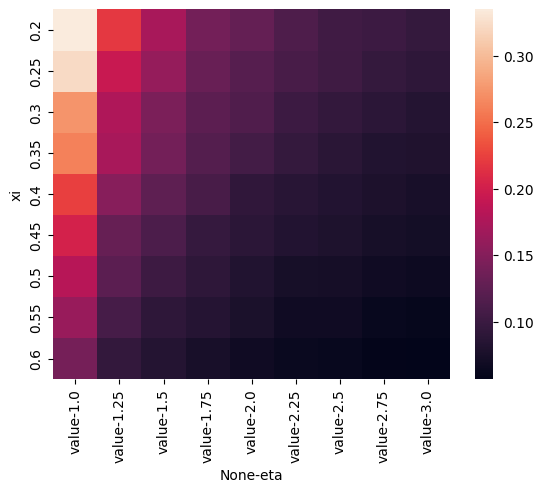

In [12]:
sns.heatmap(q)

In [16]:
y = x[["xi", "eta", "value"]].groupby(["xi", "eta"]).mean()

<StringArray>
['LC+HSLC', 'EGOSPLIT+CAS', 'OSLOM']
Length: 3, dtype: str

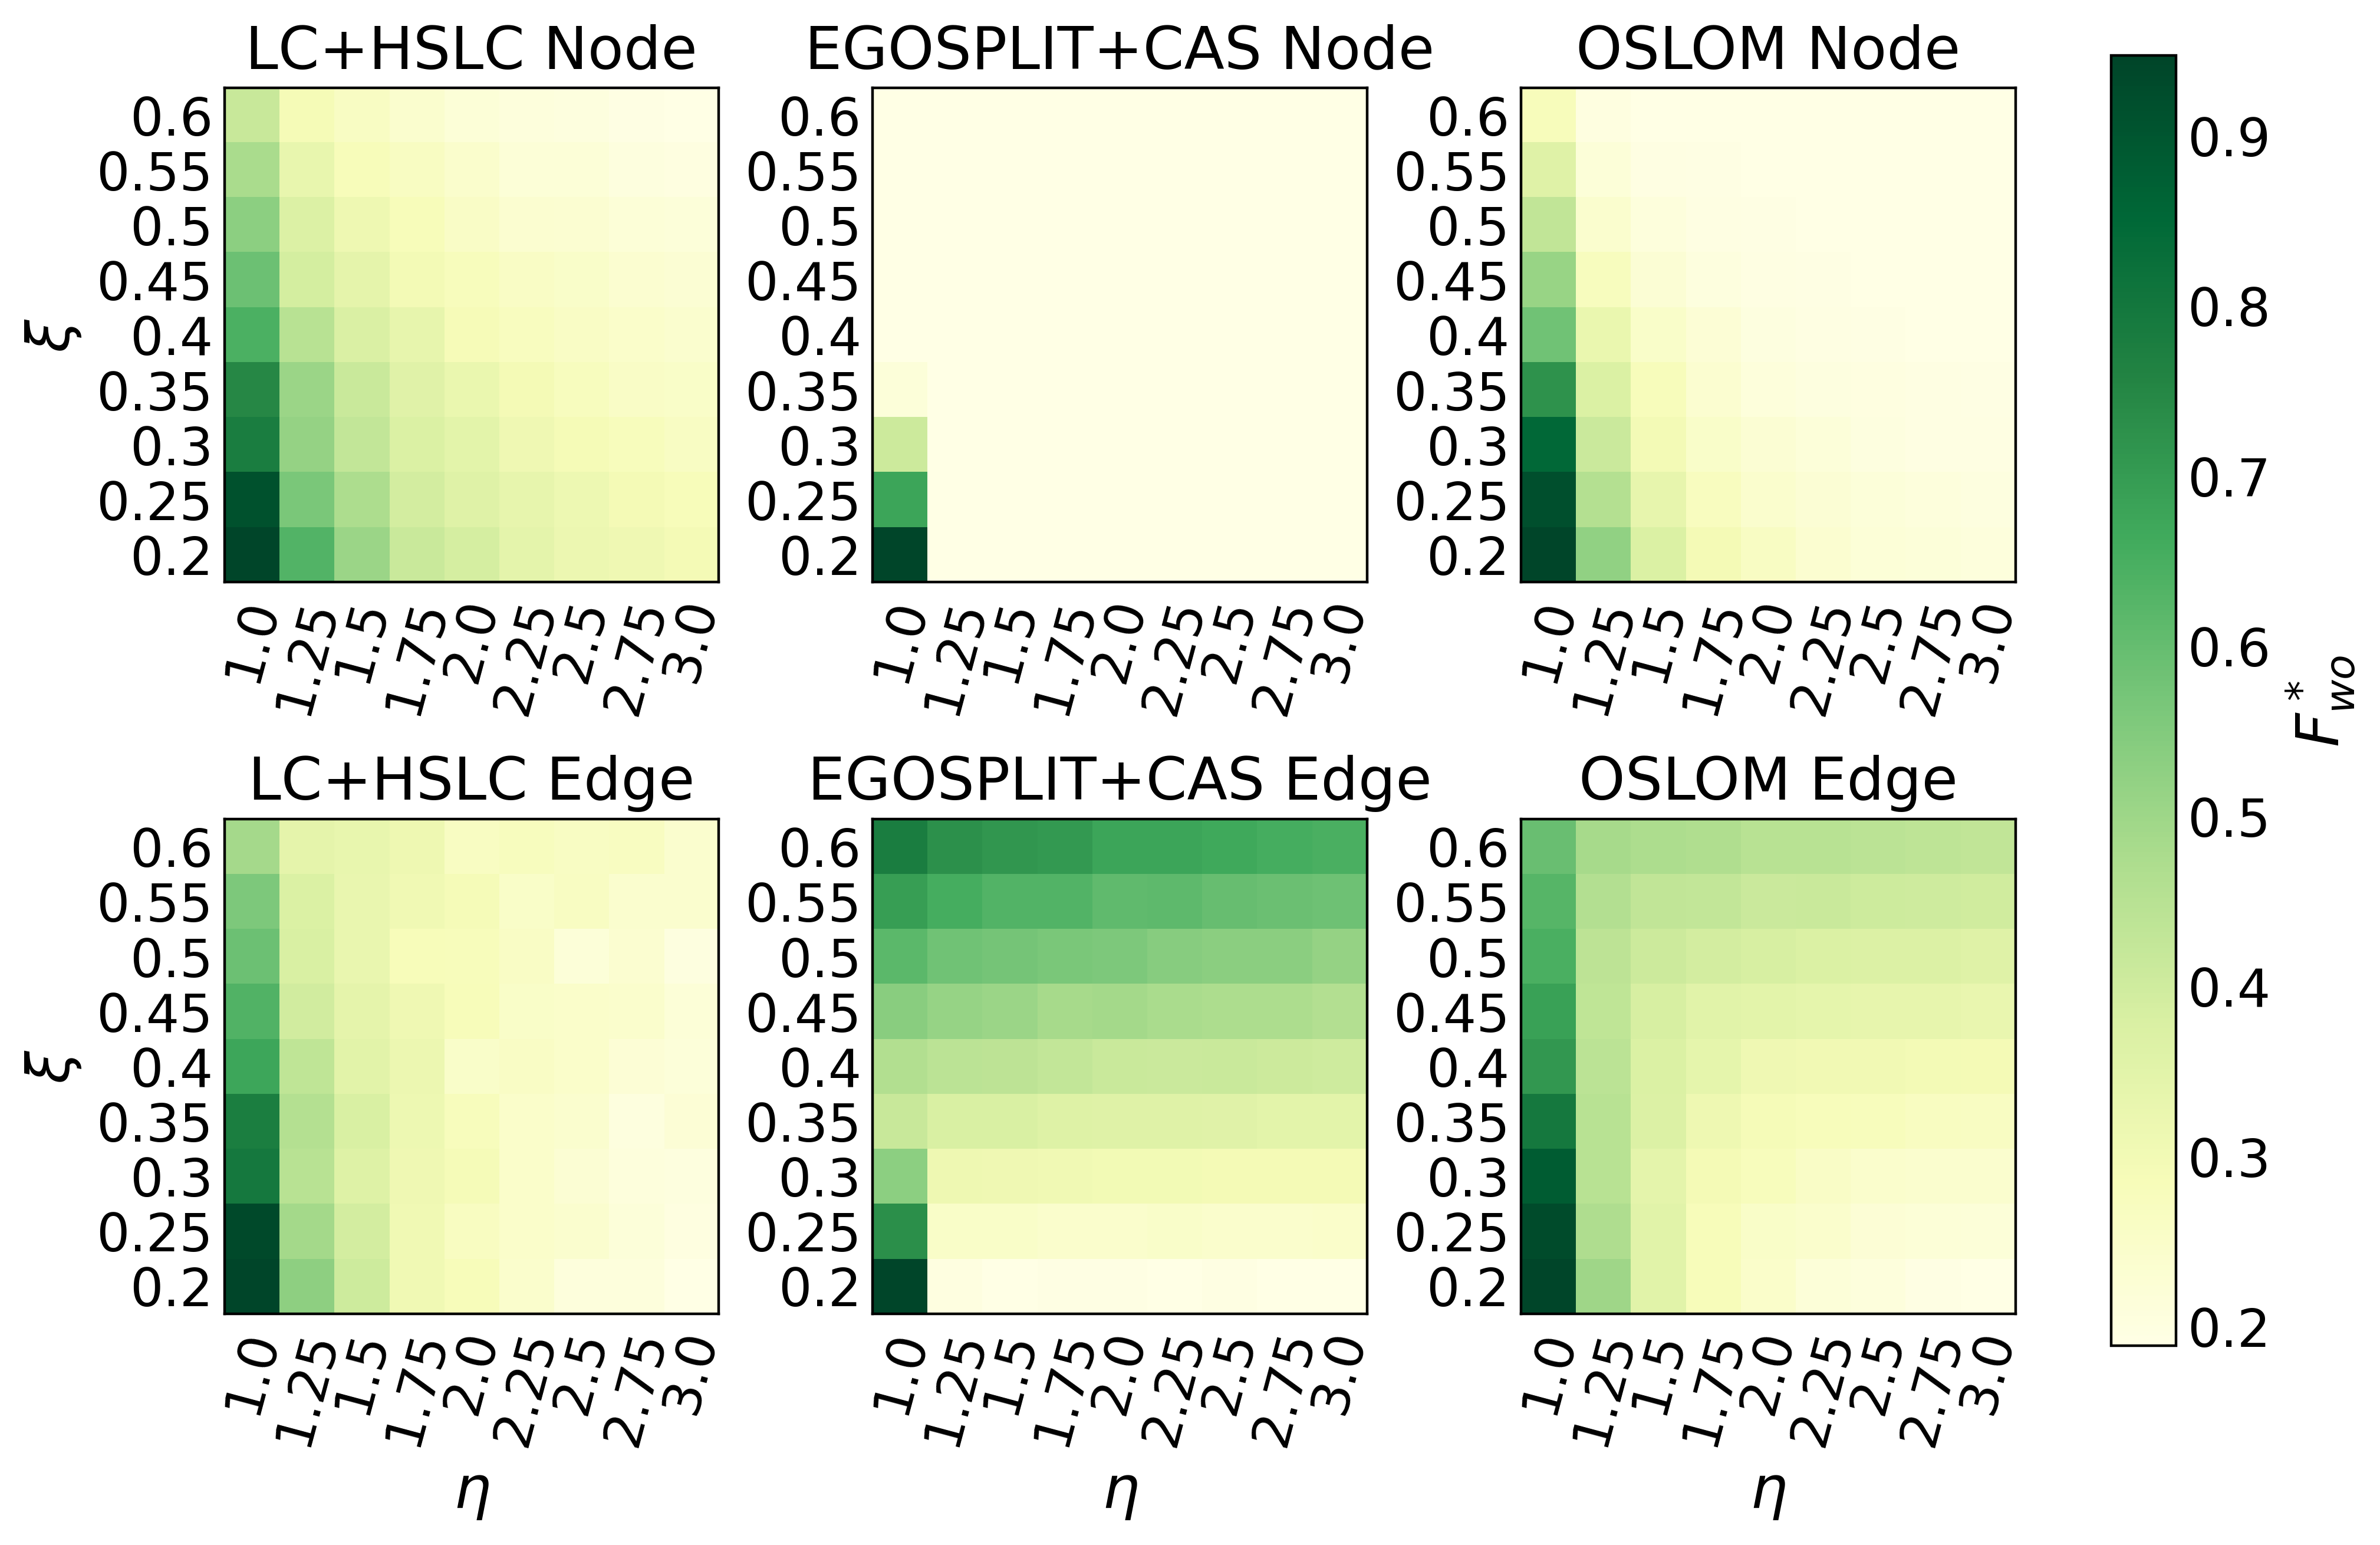

In [7]:
# make list of 2d numpy arrays
Scores = []
Cases = []
methods = df["method"].unique()
for method in methods:
    for t in ["Node", "Edge"]:
        x = df[(df["method"] == method) * (df["type"] == t)]
        y = x[["xi", "eta", "value"]].groupby(["xi", "eta"]).mean()
        q = y.unstack()
        Scores.append(q.values[::-1])
        Cases.append(method + " " + t)


## image plot
plt.style.use('_mpl-gallery-nogrid')

fig, axs = plt.subplots(2, 3, figsize=(10,6.5), dpi=400, layout="constrained")
ctr = 0
cmap = "YlGn"
for col in range(3):
    for row in range(2):
        ax = axs[row, col]
        pcm = ax.imshow(Scores[ctr], cmap=cmap)
        ax.set_title(Cases[ctr], fontsize=18)
        ax.set_yticks(ticks=list(range(len(xis))),labels=xis[::-1]);
        ax.set_xticks(ticks=list(range(len(etas))),labels=etas, rotation=75);
        ax.tick_params(labelsize=16)
        if row==1:
            ax.set_xlabel(r'$\eta$', fontsize=18)
        if col==0:
            ax.set_ylabel(r'$\xi$', fontsize=18)
        ctr += 1
cbar = fig.colorbar(pcm, ax=axs[:, :], shrink=0.95);
cbar.ax.tick_params(labelsize=16)
cbar.set_label(r'$F^*_{wo}$', fontsize=18)
plt.savefig('heatmap_grid.pdf', bbox_inches='tight');

In [42]:
pal = sns.color_palette("deep")
pal

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

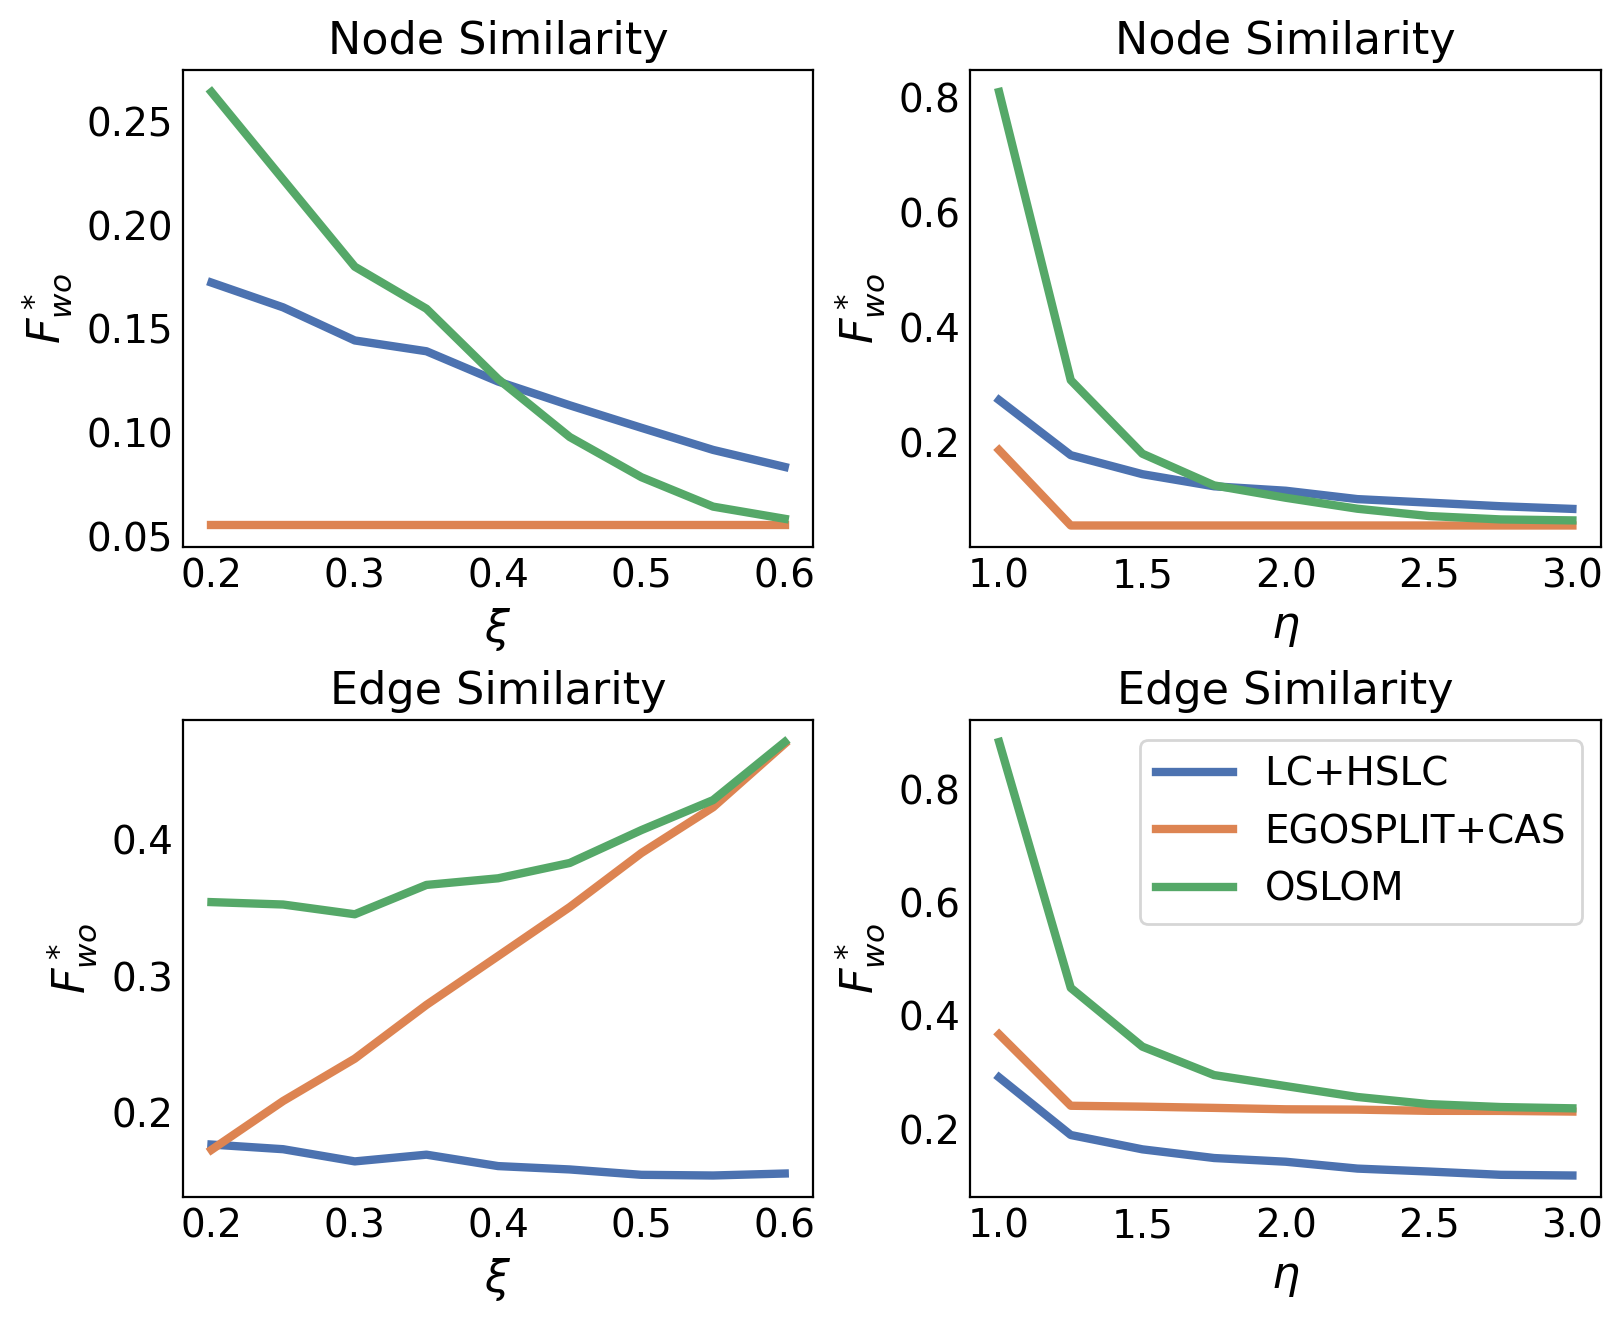

In [45]:
fig, axs = plt.subplots(2, 2, figsize=(8,6.5), dpi=200, layout="constrained")
methods = df["method"].unique()
for i, method in enumerate(methods):
    for row, t in enumerate(["Node", "Edge"]):
        x = df[(df["method"] == method) * (df["type"] == t) * (df["eta"] == 1.5)]
        q = x[["xi", "run", "value"]].groupby(["xi"]).mean()
        xs = q.index.values
        vals = q["value"].values
        axs[row, 0].plot(xs, vals, label=method, color=pal[i], linewidth=3)

        x = df[(df["method"] == method) * (df["type"] == t) * (df["xi"] == 0.3)]
        q = x[["eta", "run", "value"]].groupby(["eta"]).mean()
        es = q.index.values
        vals = q["value"].values
        axs[row, 1].plot(es, vals, label=method, color=pal[i], linewidth=3)

for ax in axs.flatten():
    ax.tick_params(labelsize=14)
    ax.set_ylabel(r"$F^*_{wo}$", fontsize=16)
axs[0,0].set_xlabel(r"$\xi$", fontsize=16)
axs[0,1].set_xlabel(r"$\eta$", fontsize=16)
axs[1,0].set_xlabel(r"$\xi$", fontsize=16)
axs[1,1].set_xlabel(r"$\eta$", fontsize=16)
axs[0,0].set_title("Node Similarity", fontsize=16)
axs[1,0].set_title("Edge Similarity", fontsize=16)
axs[0,1].set_title("Node Similarity", fontsize=16)
axs[1,1].set_title("Edge Similarity", fontsize=16)
axs[1,1].legend(fontsize=14)
plt.savefig('linegraph_grid.pdf', bbox_inches='tight');